In [1]:
import os

# CLEAN ALL conflicting Spark env vars
os.environ.pop("SPARK_HOME", None)
os.environ.pop("PYSPARK_SUBMIT_ARGS", None)
os.environ.pop("PYSPARK_PYTHON", None)
os.environ.pop("PYSPARK_DRIVER_PYTHON", None)

from pyspark.sql import SparkSession

spark = SparkSession.builder \
    .master("local[*]") \
    .appName("Taxi Demand Modeling") \
    .config("spark.driver.memory", "2g") \
    .config("spark.ui.enabled", "false") \
    .getOrCreate()

print("Spark initialized successfully")

26/04/07 11:26:46 WARN Utils: Your hostname, Prashants-MacBook-Air.local resolves to a loopback address: 127.0.0.1; using 192.168.0.26 instead (on interface en0)
26/04/07 11:26:46 WARN Utils: Set SPARK_LOCAL_IP if you need to bind to another address
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
26/04/07 11:26:47 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


Spark initialized successfully


In [2]:
raw_path = "/Users/prashant/Desktop/Projects/CRN-Taxi/yellow_taxi/yellow_tripdata_*.csv"

df_raw = spark.read \
    .option("header", True) \
    .option("inferSchema", True) \
    .csv(raw_path)

print("Raw Data Loaded")
print("Rows:", df_raw.count())
print("Columns:", len(df_raw.columns))

Raw Data Loaded


Rows: 47248845
Columns: 19


In [3]:
df_demand = spark.read.parquet(
    "/Users/prashant/Desktop/Projects/CRN-Taxi/yellow_taxi/yellow_taxi/model_input/final_predictions"
)

print("Demand Loaded")
print("Rows:", df_demand.count())
print("Columns:", len(df_demand.columns))

26/04/07 11:27:14 WARN DataSource: [COLUMN_ALREADY_EXISTS] The column `year_month` already exists. Consider to choose another name or rename the existing column.


Demand Loaded
Rows: 10209012
Columns: 44


In [4]:
# ================================
# 1. RAW DATA INSPECTION
# ================================

print("==== RAW DATA SCHEMA ====")
df_raw.printSchema()

print("==== RAW DATA SAMPLE ====")
df_raw.show(5, truncate=False)


# ================================
# 2. DEMAND DATA INSPECTION
# ================================

print("==== DEMAND DATA SCHEMA ====")
df_demand.printSchema()

print("==== DEMAND DATA SAMPLE ====")
df_demand.show(5, truncate=False)

==== RAW DATA SCHEMA ====
root
 |-- VendorID: string (nullable = true)
 |-- tpep_pickup_datetime: string (nullable = true)
 |-- tpep_dropoff_datetime: string (nullable = true)
 |-- passenger_count: string (nullable = true)
 |-- trip_distance: string (nullable = true)
 |-- pickup_longitude: string (nullable = true)
 |-- pickup_latitude: string (nullable = true)
 |-- RateCodeID: string (nullable = true)
 |-- store_and_fwd_flag: string (nullable = true)
 |-- dropoff_longitude: string (nullable = true)
 |-- dropoff_latitude: string (nullable = true)
 |-- payment_type: string (nullable = true)
 |-- fare_amount: string (nullable = true)
 |-- extra: string (nullable = true)
 |-- mta_tax: string (nullable = true)
 |-- tip_amount: string (nullable = true)
 |-- tolls_amount: string (nullable = true)
 |-- improvement_surcharge: string (nullable = true)
 |-- total_amount: string (nullable = true)

==== RAW DATA SAMPLE ====
+--------+--------------------+---------------------+---------------+------

26/04/07 11:27:15 WARN SparkStringUtils: Truncated the string representation of a plan since it was too large. This behavior can be adjusted by setting 'spark.sql.debug.maxToStringFields'.


+-------+-------+-------------------+-----------+------+--------+------------+---------------+-----+-----+-----+---------+----+-----------+-----+-------------------+------------------+--------------------+-----------------+------------+----------+--------+-------------+---------------------+---------+------+-------+---------+---------+--------------+--------------+---------+-------------+--------------------+---------------+----------+-----------+----------+-----------+----------+-------+------------------+------------------+------------------+
|lat_bin|lon_bin|timestamp          |pickup_hour|demand|avg_fare|avg_distance|long_trip_ratio|lag_1|lag_2|lag_3|rolling_3|hour|day_of_week|month|hour_sin           |hour_cos          |loc_avg_demand      |loc_std_demand   |is_peak_hour|is_weekend|is_night|demand_vs_avg|demand_zscore        |rolling_6|lag_24|lag_168|trend_1_3|trend_1_6|is_active_zone|peak_intensity|log_lag_1|log_rolling_6|hour_x_zone         |recent_activity|log_demand|persistenc

In [5]:
from pyspark.sql.functions import min, max, countDistinct

# ================================
# 3. TIME RANGE CHECK
# ================================

print("==== RAW TIME RANGE ====")
df_raw.select(
    min("tpep_pickup_datetime"),
    max("tpep_pickup_datetime")
).show()

print("==== DEMAND TIME RANGE ====")
df_demand.select(
    min("timestamp"),
    max("timestamp")
).show()


# ================================
# 4. GRANULARITY CHECK
# ================================

print("==== UNIQUE TIME VALUES (DEMAND) ====")
df_demand.select("timestamp").distinct().count()

print("==== SAMPLE TIME VALUES ====")
df_demand.select("timestamp").distinct().orderBy("timestamp").show(10, False)


# ================================
# 5. SPATIAL STRUCTURE CHECK
# ================================

print("==== ZONE STRUCTURE ====")
df_demand.select("lat_bin", "lon_bin").distinct().count()

df_demand.select("lat_bin", "lon_bin").distinct().show(10)


# ================================
# 6. DEMAND VALIDATION
# ================================

print("==== DEMAND DISTRIBUTION ====")
df_demand.selectExpr(
    "min(demand)", "max(demand)", "avg(demand)"
).show()


# ================================
# 7. DUPLICATE CHECK (CRITICAL)
# ================================

print("==== DUPLICATE CHECK ====")
df_demand.groupBy("lat_bin", "lon_bin", "timestamp") \
    .count() \
    .filter("count > 1") \
    .show()

==== RAW TIME RANGE ====


+-------------------------+-------------------------+
|min(tpep_pickup_datetime)|max(tpep_pickup_datetime)|
+-------------------------+-------------------------+
|      2015-01-01 00:00:00|      2016-03-31 23:59:59|
+-------------------------+-------------------------+

==== DEMAND TIME RANGE ====
+-------------------+-------------------+
|     min(timestamp)|     max(timestamp)|
+-------------------+-------------------+
|2015-01-08 07:00:00|2016-03-31 23:00:00|
+-------------------+-------------------+

==== UNIQUE TIME VALUES (DEMAND) ====
==== SAMPLE TIME VALUES ====
+-------------------+
|timestamp          |
+-------------------+
|2015-01-08 07:00:00|
|2015-01-08 08:00:00|
|2015-01-08 09:00:00|
|2015-01-08 10:00:00|
|2015-01-08 11:00:00|
|2015-01-08 12:00:00|
|2015-01-08 13:00:00|
|2015-01-08 14:00:00|
|2015-01-08 15:00:00|
|2015-01-08 16:00:00|
+-------------------+
only showing top 10 rows

==== ZONE STRUCTURE ====
+-------+-------+
|lat_bin|lon_bin|
+-------+-------+
|   4083| 

+-------+-------+---------+-----+
|lat_bin|lon_bin|timestamp|count|
+-------+-------+---------+-----+
+-------+-------+---------+-----+



In [6]:
from pyspark.sql.functions import col, floor

# Cast + create bins from raw data
df_raw_spatial = df_raw \
    .withColumn("pickup_latitude", col("pickup_latitude").cast("double")) \
    .withColumn("pickup_longitude", col("pickup_longitude").cast("double")) \
    .withColumn("lat_bin", floor(col("pickup_latitude") * 100)) \
    .withColumn("lon_bin", floor(col("pickup_longitude") * 100))

# Aggregate raw into spatial counts
df_raw_bins = df_raw_spatial.groupBy("lat_bin", "lon_bin") \
    .count() \
    .withColumnRenamed("count", "raw_trip_count")

print("Raw spatial bins created")

Raw spatial bins created


In [7]:
# Aggregate demand dataset spatially
df_demand_bins = df_demand.groupBy("lat_bin", "lon_bin") \
    .sum("demand") \
    .withColumnRenamed("sum(demand)", "aggregated_demand")

# Join both
df_spatial_compare = df_raw_bins.join(
    df_demand_bins,
    on=["lat_bin", "lon_bin"],
    how="outer"
)

# Fill nulls
df_spatial_compare = df_spatial_compare.fillna(0)

# ================================
# 1. COVERAGE CHECK
# ================================

print("Total Raw Zones:", df_raw_bins.count())
print("Total Demand Zones:", df_demand_bins.count())
print("Total Combined Zones:", df_spatial_compare.count())


# ================================
# 2. MISSING ZONES
# ================================

print("Zones in RAW but missing in DEMAND:")
df_spatial_compare.filter("aggregated_demand = 0 AND raw_trip_count > 0").show(10)

print("Zones in DEMAND but not in RAW:")
df_spatial_compare.filter("raw_trip_count = 0 AND aggregated_demand > 0").show(10)


# ================================
# 3. DISTRIBUTION CHECK
# ================================

df_spatial_compare.selectExpr(
    "corr(raw_trip_count, aggregated_demand) as spatial_correlation"
).show()


# ================================
# 4. TOP ZONES COMPARISON
# ================================

print("Top zones in RAW:")
df_raw_bins.orderBy(col("raw_trip_count").desc()).show(10)

print("Top zones in DEMAND:")
df_demand_bins.orderBy(col("aggregated_demand").desc()).show(10)

Total Raw Zones: 4710
Total Demand Zones: 948


Total Combined Zones: 4710
Zones in RAW but missing in DEMAND:


+-------+-------+--------------+-----------------+
|lat_bin|lon_bin|raw_trip_count|aggregated_demand|
+-------+-------+--------------+-----------------+
|   4068|  -7364|             4|                0|
|    478|  -7396|             1|                0|
|   4150|  -7500|             3|                0|
|   4075|  -7353|             2|                0|
|   4069|  -7439|             5|                0|
|   4084|  -7408|             6|                0|
|   4103|  -7363|             6|                0|
|   4006|  -7335|             1|                0|
|   4075|  -7362|             3|                0|
|   4086|  -7420|             5|                0|
+-------+-------+--------------+-----------------+
only showing top 10 rows

Zones in DEMAND but not in RAW:


+-------+-------+--------------+-----------------+
|lat_bin|lon_bin|raw_trip_count|aggregated_demand|
+-------+-------+--------------+-----------------+
+-------+-------+--------------+-----------------+



+-------------------+
|spatial_correlation|
+-------------------+
| 0.9953282199550859|
+-------------------+

Top zones in RAW:


+-------+-------+--------------+
|lat_bin|lon_bin|raw_trip_count|
+-------+-------+--------------+
|   4075|  -7398|       2886211|
|   4074|  -7399|       2254234|
|   4076|  -7399|       2220533|
|   4075|  -7399|       2168503|
|   4075|  -7400|       1920268|
|   4074|  -7400|       1913847|
|   4076|  -7397|       1841593|
|   4076|  -7398|       1773622|
|   4077|  -7396|       1742431|
|   4073|  -7399|       1678884|
+-------+-------+--------------+
only showing top 10 rows

Top zones in DEMAND:
+-------+-------+-----------------+
|lat_bin|lon_bin|aggregated_demand|
+-------+-------+-----------------+
|   4075|  -7398|          2704092|
|   4074|  -7399|          2115058|
|   4076|  -7399|          2075940|
|   4075|  -7399|          2018457|
|   4074|  -7400|          1795771|
|   4075|  -7400|          1793096|
|   4076|  -7397|          1727077|
|   4076|  -7398|          1656451|
|   4077|  -7396|          1630638|
|   4073|  -7399|          1572179|
+-------+-------+------

In [8]:
from pyspark.sql.functions import col, lag
from pyspark.sql.window import Window

# ================================
# 1. SORT + CHECK GAPS
# ================================

window_time = Window.orderBy("timestamp")

df_time_check = df_demand \
    .select("timestamp") \
    .distinct() \
    .orderBy("timestamp") \
    .withColumn("prev_time", lag("timestamp").over(window_time)) \
    .withColumn("diff_hours",
        (col("timestamp").cast("long") - col("prev_time").cast("long")) / 3600
    )

print("==== TIME GAPS (>1 hour) ====")
df_time_check.filter("diff_hours > 1").show(20, False)


# ================================
# 2. TOTAL UNIQUE HOURS
# ================================

total_hours = df_demand.select("timestamp").distinct().count()
print("Total unique hours:", total_hours)

==== TIME GAPS (>1 hour) ====


26/04/07 11:28:37 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/04/07 11:28:37 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/04/07 11:28:37 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/04/07 11:28:38 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/04/07 11:28:38 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/04/07 11:28:38 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/04/07 1

+---------+---------+----------+
|timestamp|prev_time|diff_hours|
+---------+---------+----------+
+---------+---------+----------+

Total unique hours: 10769


In [9]:
from pyspark.sql.functions import date_trunc

# ================================
# 3. RAW → HOURLY BUCKET
# ================================

df_raw_time = df_raw \
    .withColumn("tpep_pickup_datetime", col("tpep_pickup_datetime").cast("timestamp")) \
    .withColumn("timestamp", date_trunc("hour", col("tpep_pickup_datetime")))

raw_hours = df_raw_time.select("timestamp").distinct()

demand_hours = df_demand.select("timestamp").distinct()

# ================================
# 4. COVERAGE COMPARISON
# ================================

missing_in_demand = raw_hours.join(demand_hours, on="timestamp", how="left_anti")
extra_in_demand = demand_hours.join(raw_hours, on="timestamp", how="left_anti")

print("Hours in RAW but missing in DEMAND:")
missing_in_demand.show(10)

print("Hours in DEMAND but not in RAW:")
extra_in_demand.show(10)

Hours in RAW but missing in DEMAND:


+-------------------+
|          timestamp|
+-------------------+
|2015-01-05 16:00:00|
|2015-01-05 04:00:00|
|2015-01-01 15:00:00|
|2015-01-04 00:00:00|
|2015-01-06 20:00:00|
|2015-01-02 06:00:00|
|2015-01-01 05:00:00|
|2015-01-06 12:00:00|
|2015-01-02 02:00:00|
|2015-01-03 07:00:00|
+-------------------+
only showing top 10 rows

Hours in DEMAND but not in RAW:


+-------------------+
|          timestamp|
+-------------------+
|2015-02-05 20:00:00|
|2015-02-12 18:00:00|
|2015-02-17 06:00:00|
|2015-02-04 12:00:00|
|2015-02-11 19:00:00|
|2015-02-08 03:00:00|
|2015-02-10 21:00:00|
|2015-02-21 15:00:00|
|2015-02-01 16:00:00|
|2015-02-03 07:00:00|
+-------------------+
only showing top 10 rows



In [10]:
df_demand.filter("demand > 0").join(
    df_raw_time,
    on="timestamp",
    how="left_anti"
).show(10)

26/04/07 11:29:13 WARN TaskMemoryManager: Failed to allocate a page (268435456 bytes), try again.


[147.282s][warning][gc,alloc] Executor task launch worker for task 1.0 in stage 130.0 (TID 914): Retried waiting for GCLocker too often allocating 33554434 words


+---------+-------+-------+-----------+------+--------+------------+---------------+-----+-----+-----+---------+----+-----------+-----+--------+--------+--------------+--------------+------------+----------+--------+-------------+-------------+---------+------+-------+---------+---------+--------------+--------------+---------+-------------+-----------+---------------+----------+-----------+----------+-----------+----------+-------+--------+--------+----------------+
|timestamp|lat_bin|lon_bin|pickup_hour|demand|avg_fare|avg_distance|long_trip_ratio|lag_1|lag_2|lag_3|rolling_3|hour|day_of_week|month|hour_sin|hour_cos|loc_avg_demand|loc_std_demand|is_peak_hour|is_weekend|is_night|demand_vs_avg|demand_zscore|rolling_6|lag_24|lag_168|trend_1_3|trend_1_6|is_active_zone|peak_intensity|log_lag_1|log_rolling_6|hour_x_zone|recent_activity|log_demand|persistence|has_demand|pickup_date|year_month|zone_id|pred_raw|pred_log|final_prediction|
+---------+-------+-------+-----------+------+--------+-

In [11]:
# ================================
# 1. PREPARE DATA FOR VISUALIZATION
# ================================

from pyspark.sql.functions import col, avg

# Aggregate demand per zone
df_viz = df_demand.groupBy("lat_bin", "lon_bin", "zone_id") \
    .agg(
        avg("demand").alias("avg_demand")
    )

# Convert to pandas (sample if too large)
pdf = df_viz.sample(fraction=0.2, seed=42).toPandas()

print("Shape:", pdf.shape)
pdf.head()

Shape: (190, 4)


,lat_bin,lon_bin,zone_id,avg_demand
0,4058,-7392,4,0.001207
1,4070,-7386,3,0.019315
2,4087,-7384,0,0.002971
3,4065,-7401,4,0.173368
4,4077,-7391,2,0.575727


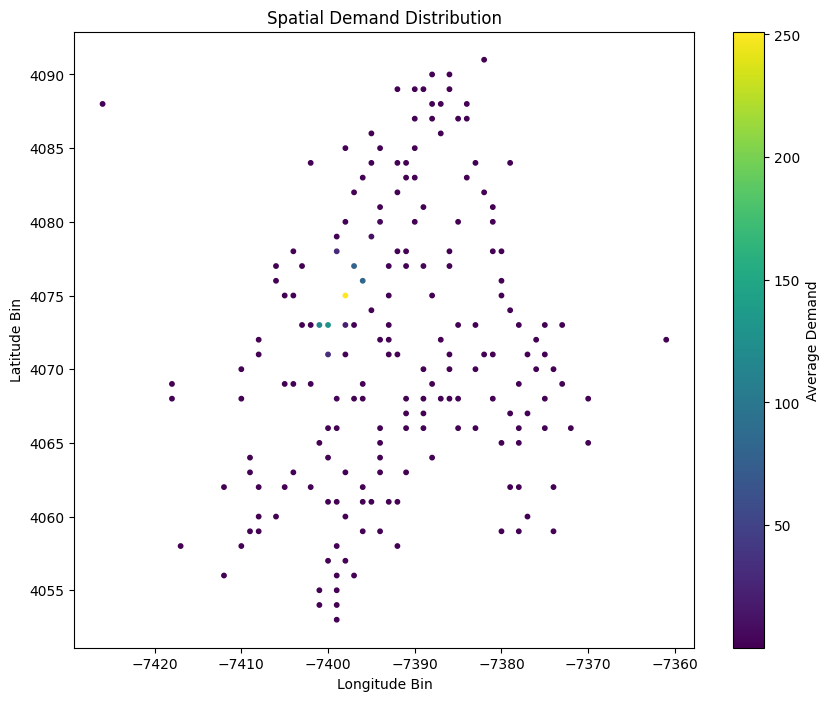

In [12]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 8))

plt.scatter(
    pdf["lon_bin"],
    pdf["lat_bin"],
    s=10,
    c=pdf["avg_demand"]
)

plt.colorbar(label="Average Demand")
plt.xlabel("Longitude Bin")
plt.ylabel("Latitude Bin")
plt.title("Spatial Demand Distribution")

plt.show()

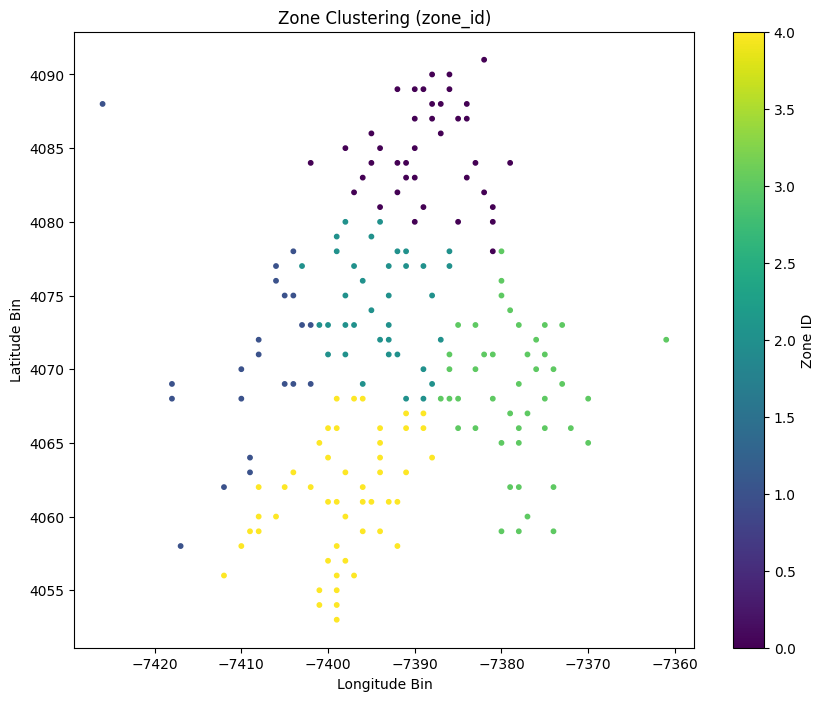

In [13]:
plt.figure(figsize=(10, 8))

plt.scatter(
    pdf["lon_bin"],
    pdf["lat_bin"],
    s=10,
    c=pdf["zone_id"]
)

plt.colorbar(label="Zone ID")
plt.xlabel("Longitude Bin")
plt.ylabel("Latitude Bin")
plt.title("Zone Clustering (zone_id)")

plt.show()

In [14]:
from pyspark.sql.functions import col, year, hour, dayofweek, month

# ================================
# FILTER 2015 DATA
# ================================

df_2015 = df_raw \
    .withColumn("pickup_ts", col("tpep_pickup_datetime").cast("timestamp")) \
    .filter(year("pickup_ts") == 2015)

print("2015 Rows:", df_2015.count())

# ================================
# EXTRACT TIME FEATURES
# ================================

df_2015 = df_2015 \
    .withColumn("hour", hour("pickup_ts")) \
    .withColumn("day_of_week", dayofweek("pickup_ts")) \
    .withColumn("month", month("pickup_ts"))

2015 Rows: 12748986


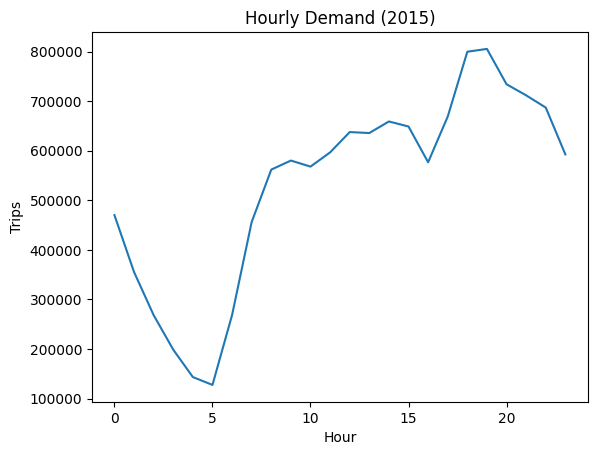

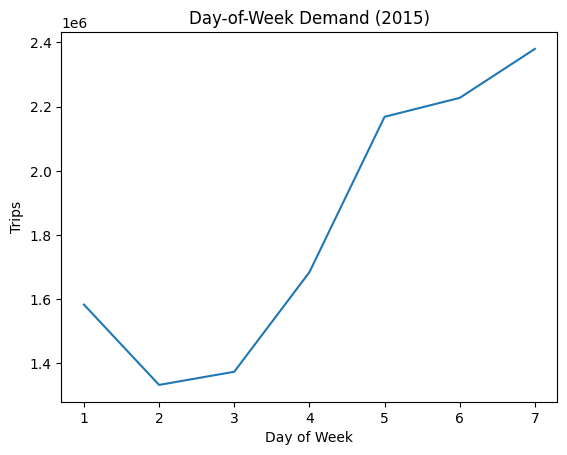

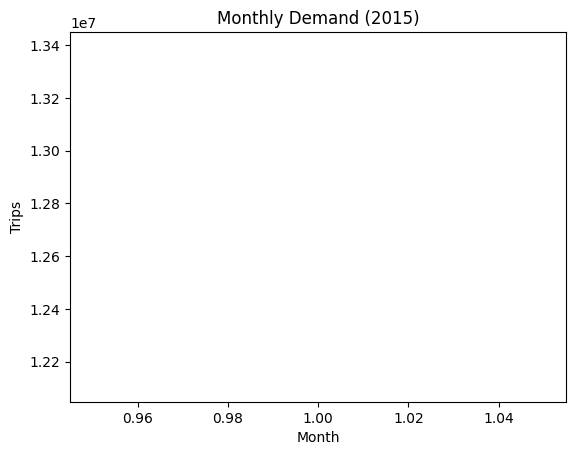

In [15]:
import matplotlib.pyplot as plt

# ================================
# HOURLY DEMAND
# ================================

hourly = df_2015.groupBy("hour").count().orderBy("hour").toPandas()

plt.figure()
plt.plot(hourly["hour"], hourly["count"])
plt.title("Hourly Demand (2015)")
plt.xlabel("Hour")
plt.ylabel("Trips")
plt.show()


# ================================
# DAY OF WEEK DEMAND
# ================================

dow = df_2015.groupBy("day_of_week").count().orderBy("day_of_week").toPandas()

plt.figure()
plt.plot(dow["day_of_week"], dow["count"])
plt.title("Day-of-Week Demand (2015)")
plt.xlabel("Day of Week")
plt.ylabel("Trips")
plt.show()


# ================================
# MONTHLY DEMAND
# ================================

monthly = df_2015.groupBy("month").count().orderBy("month").toPandas()

plt.figure()
plt.plot(monthly["month"], monthly["count"])
plt.title("Monthly Demand (2015)")
plt.xlabel("Month")
plt.ylabel("Trips")
plt.show()

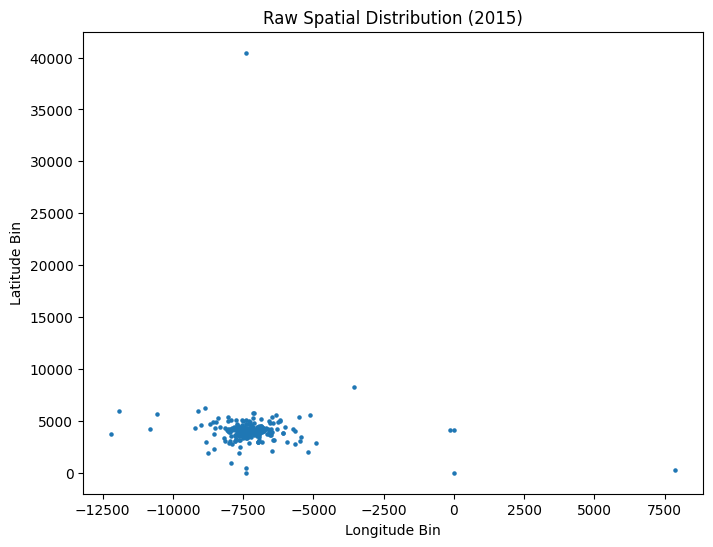

In [16]:
from pyspark.sql.functions import floor

# ================================
# CREATE SPATIAL BINS
# ================================

df_2015_spatial = df_2015 \
    .withColumn("pickup_latitude", col("pickup_latitude").cast("double")) \
    .withColumn("pickup_longitude", col("pickup_longitude").cast("double")) \
    .withColumn("lat_bin", floor(col("pickup_latitude") * 100)) \
    .withColumn("lon_bin", floor(col("pickup_longitude") * 100))

spatial = df_2015_spatial.groupBy("lat_bin", "lon_bin") \
    .count() \
    .toPandas()

plt.figure(figsize=(8,6))
plt.scatter(spatial["lon_bin"], spatial["lat_bin"], s=5)
plt.title("Raw Spatial Distribution (2015)")
plt.xlabel("Longitude Bin")
plt.ylabel("Latitude Bin")
plt.show()

In [17]:
from pyspark.sql.functions import col, year

# ================================
# FILTER + CAST (VERY IMPORTANT)
# ================================

df_2015 = df_raw \
    .withColumn("pickup_ts", col("tpep_pickup_datetime").cast("timestamp")) \
    .withColumn("trip_distance", col("trip_distance").cast("double")) \
    .withColumn("fare_amount", col("fare_amount").cast("double")) \
    .withColumn("passenger_count", col("passenger_count").cast("int")) \
    .filter(year("pickup_ts") == 2015)

print("2015 Rows:", df_2015.count())

2015 Rows: 12748986


In [18]:
from pyspark.sql.functions import min, max, avg, expr

# ================================
# BASIC STATS
# ================================

df_2015.select(
    min("trip_distance").alias("min_distance"),
    max("trip_distance").alias("max_distance"),
    avg("trip_distance").alias("avg_distance"),

    min("fare_amount").alias("min_fare"),
    max("fare_amount").alias("max_fare"),
    avg("fare_amount").alias("avg_fare"),

    min("passenger_count").alias("min_passenger"),
    max("passenger_count").alias("max_passenger"),
    avg("passenger_count").alias("avg_passenger")
).show()

+------------+------------+------------------+--------+--------+------------------+-------------+-------------+------------------+
|min_distance|max_distance|      avg_distance|min_fare|max_fare|          avg_fare|min_passenger|max_passenger|     avg_passenger|
+------------+------------+------------------+--------+--------+------------------+-------------+-------------+------------------+
|         0.0|1.54200045E7|13.459129611562718|  -450.0|  4008.0|11.905659425776989|            0|            9|1.6814908260154964|
+------------+------------+------------------+--------+--------+------------------+-------------+-------------+------------------+



In [19]:
# ================================
# PERCENTILES (OUTLIER DETECTION)
# ================================

df_2015.selectExpr(
    "percentile_approx(trip_distance, 0.5) as median_distance",
    "percentile_approx(trip_distance, 0.9) as p90_distance",
    "percentile_approx(trip_distance, 0.99) as p99_distance",

    "percentile_approx(fare_amount, 0.5) as median_fare",
    "percentile_approx(fare_amount, 0.9) as p90_fare",
    "percentile_approx(fare_amount, 0.99) as p99_fare"
).show()

+---------------+------------+------------+-----------+--------+--------+
|median_distance|p90_distance|p99_distance|median_fare|p90_fare|p99_fare|
+---------------+------------+------------+-----------+--------+--------+
|           1.68|        5.99|       18.22|        9.0|    22.0|    52.0|
+---------------+------------+------------+-----------+--------+--------+



In [20]:
from pyspark.sql.functions import sum, when

df_2015.select(
    sum(when(col("trip_distance").isNull(), 1).otherwise(0)).alias("null_distance"),
    sum(when(col("fare_amount").isNull(), 1).otherwise(0)).alias("null_fare"),
    sum(when(col("passenger_count").isNull(), 1).otherwise(0)).alias("null_passenger"),

    sum(when(col("trip_distance") <= 0, 1).otherwise(0)).alias("zero_or_negative_distance"),
    sum(when(col("fare_amount") <= 0, 1).otherwise(0)).alias("zero_or_negative_fare")
).show()

+-------------+---------+--------------+-------------------------+---------------------+
|null_distance|null_fare|null_passenger|zero_or_negative_distance|zero_or_negative_fare|
+-------------+---------+--------------+-------------------------+---------------------+
|            0|        0|             0|                    79365|                 7666|
+-------------+---------+--------------+-------------------------+---------------------+



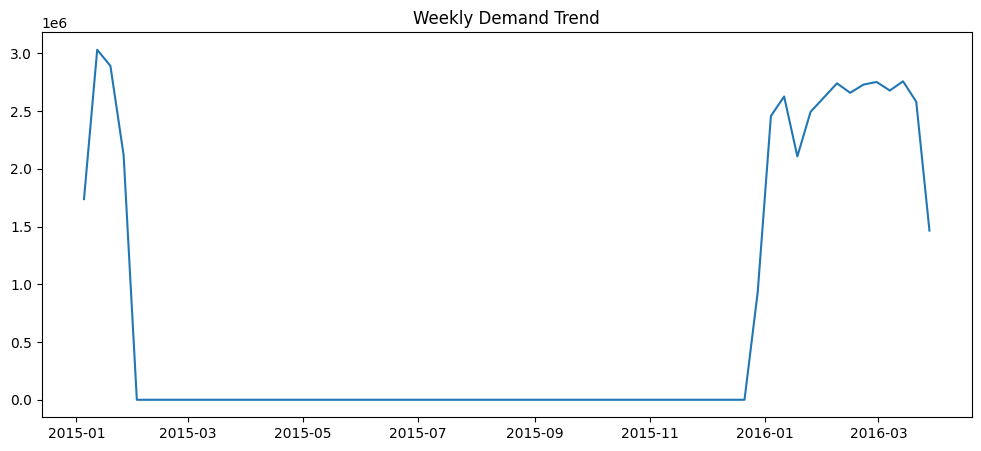

In [21]:
from pyspark.sql.functions import date_trunc

df_weekly = df_demand \
    .withColumn("week", date_trunc("week", col("timestamp"))) \
    .groupBy("week") \
    .sum("demand") \
    .orderBy("week") \
    .toPandas()

plt.figure(figsize=(12,5))
plt.plot(df_weekly["week"], df_weekly["sum(demand)"])
plt.title("Weekly Demand Trend")
plt.show()

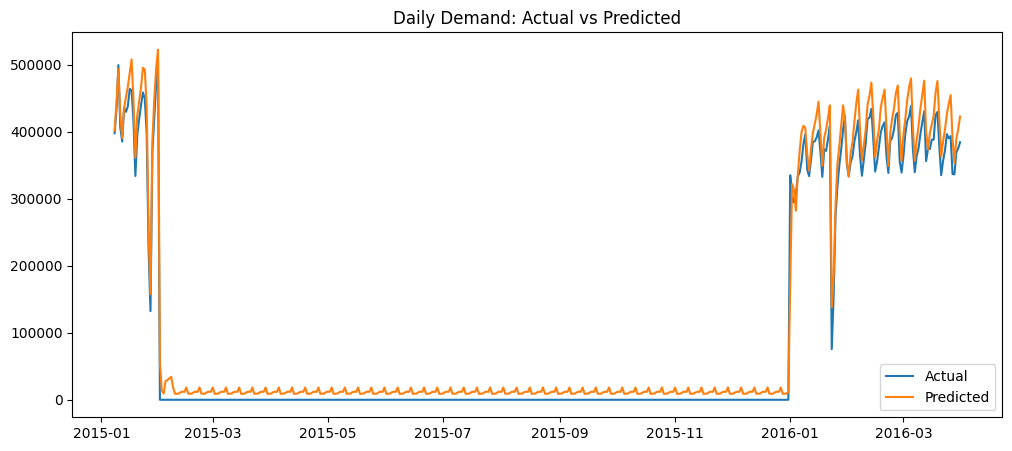

In [22]:
df_daily = df_demand \
    .withColumn("day", date_trunc("day", col("timestamp"))) \
    .groupBy("day") \
    .sum("demand", "final_prediction") \
    .orderBy("day") \
    .toPandas()

plt.figure(figsize=(12,5))
plt.plot(df_daily["day"], df_daily["sum(demand)"], label="Actual")
plt.plot(df_daily["day"], df_daily["sum(final_prediction)"], label="Predicted")

plt.legend()
plt.title("Daily Demand: Actual vs Predicted")
plt.show()

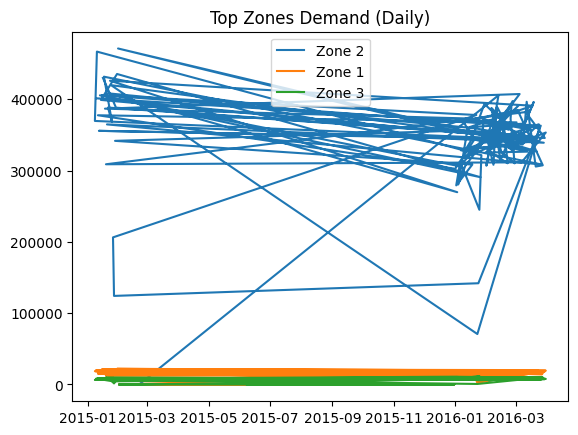

In [23]:
top_zones = df_demand.groupBy("zone_id") \
    .sum("demand") \
    .orderBy("sum(demand)", ascending=False) \
    .limit(3) \
    .select("zone_id") \
    .toPandas()["zone_id"].tolist()

df_zone = df_demand \
    .filter(col("zone_id").isin(top_zones)) \
    .withColumn("day", date_trunc("day", col("timestamp"))) \
    .groupBy("day", "zone_id") \
    .sum("demand") \
    .toPandas()

for zone in top_zones:
    subset = df_zone[df_zone["zone_id"] == zone]
    plt.plot(subset["day"], subset["sum(demand)"], label=f"Zone {zone}")

plt.legend()
plt.title("Top Zones Demand (Daily)")
plt.show()

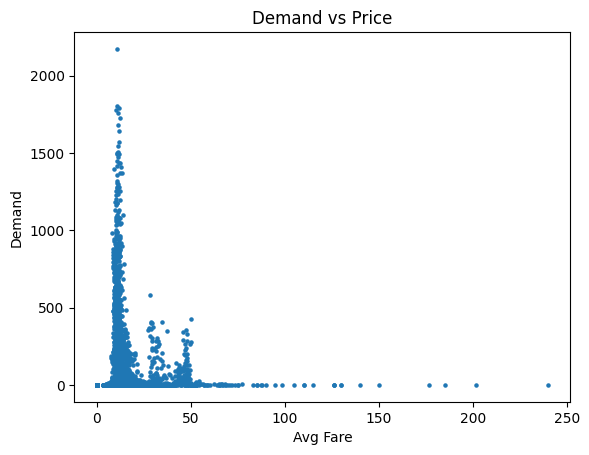

In [24]:
df_scatter = df_demand.sample(0.01).toPandas()

plt.figure()
plt.scatter(df_scatter["avg_fare"], df_scatter["demand"], s=5)
plt.xlabel("Avg Fare")
plt.ylabel("Demand")
plt.title("Demand vs Price")
plt.show()

In [25]:
from pyspark.sql.functions import col, year, date_trunc

# Cast + filter
df_2015 = df_raw \
    .withColumn("pickup_ts", col("tpep_pickup_datetime").cast("timestamp")) \
    .filter(year("pickup_ts") == 2015)

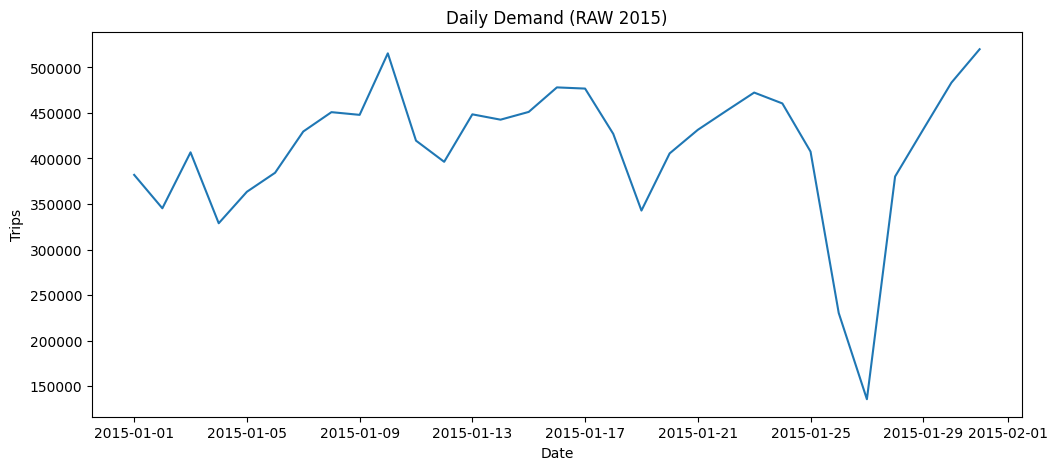

In [26]:
df_daily = df_2015 \
    .withColumn("day", date_trunc("day", col("pickup_ts"))) \
    .groupBy("day") \
    .count() \
    .orderBy("day") \
    .toPandas()

import matplotlib.pyplot as plt

plt.figure(figsize=(12,5))
plt.plot(df_daily["day"], df_daily["count"])
plt.title("Daily Demand (RAW 2015)")
plt.xlabel("Date")
plt.ylabel("Trips")
plt.show()

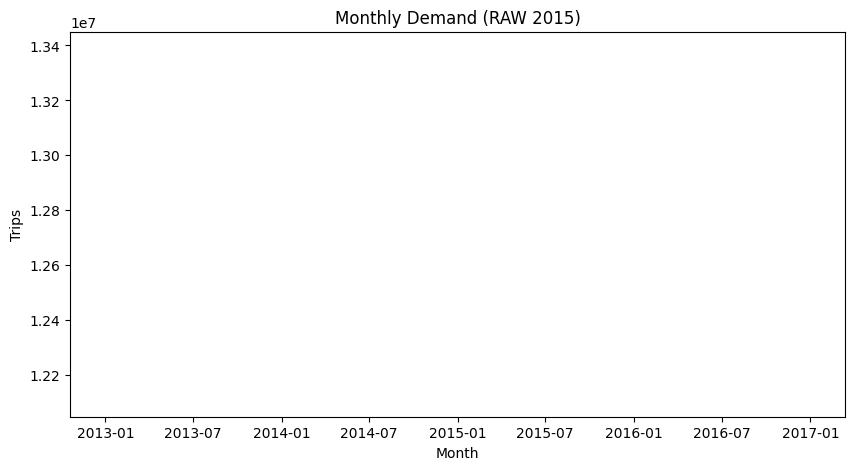

In [27]:
from pyspark.sql.functions import date_trunc

df_monthly = df_2015 \
    .withColumn("month", date_trunc("month", col("pickup_ts"))) \
    .groupBy("month") \
    .count() \
    .orderBy("month") \
    .toPandas()

import matplotlib.pyplot as plt

plt.figure(figsize=(10,5))
plt.plot(df_monthly["month"], df_monthly["count"])
plt.title("Monthly Demand (RAW 2015)")
plt.xlabel("Month")
plt.ylabel("Trips")
plt.show()

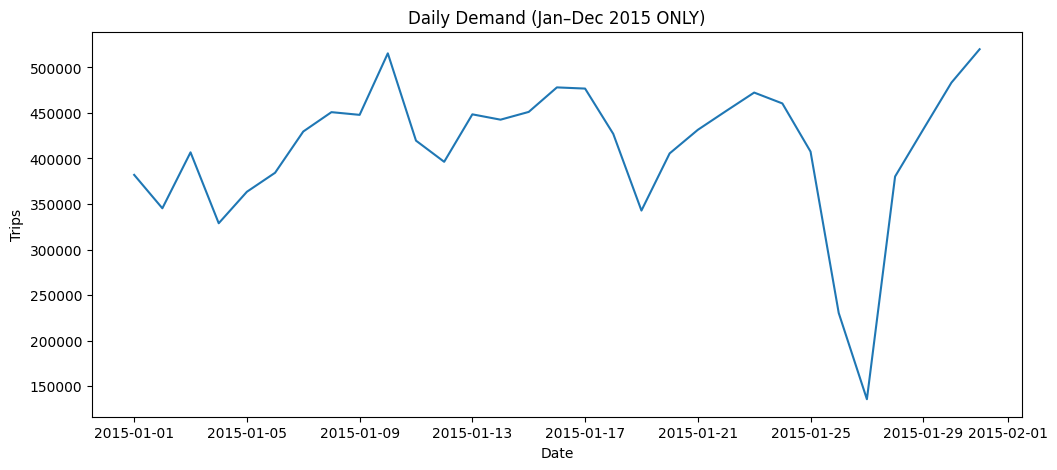

In [28]:
from pyspark.sql.functions import col, date_trunc

# ================================
# STRICT DATE FILTER
# ================================

df_2015_clean = df_raw \
    .withColumn("pickup_ts", col("tpep_pickup_datetime").cast("timestamp")) \
    .filter((col("pickup_ts") >= "2015-01-01") & (col("pickup_ts") < "2016-01-01"))

# ================================
# DAILY DEMAND
# ================================

df_daily = df_2015_clean \
    .withColumn("day", date_trunc("day", col("pickup_ts"))) \
    .groupBy("day") \
    .count() \
    .orderBy("day") \
    .toPandas()

import matplotlib.pyplot as plt

plt.figure(figsize=(12,5))
plt.plot(df_daily["day"], df_daily["count"])
plt.title("Daily Demand (Jan–Dec 2015 ONLY)")
plt.xlabel("Date")
plt.ylabel("Trips")
plt.show()

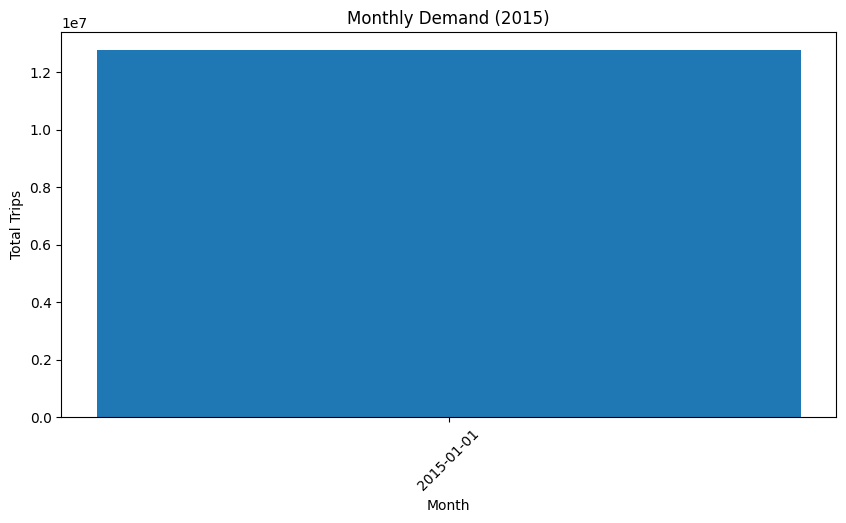

In [29]:
from pyspark.sql.functions import col, date_trunc

# ================================
# MONTHLY AGGREGATION
# ================================

df_monthly = df_2015_clean \
    .withColumn("month", date_trunc("month", col("pickup_ts"))) \
    .groupBy("month") \
    .count() \
    .orderBy("month") \
    .toPandas()

import matplotlib.pyplot as plt

plt.figure(figsize=(10,5))
plt.bar(df_monthly["month"].astype(str), df_monthly["count"])

plt.title("Monthly Demand (2015)")
plt.xlabel("Month")
plt.ylabel("Total Trips")
plt.xticks(rotation=45)
plt.show()

In [30]:
df_2015_clean.select("pickup_ts").show(5, False)

+-------------------+
|pickup_ts          |
+-------------------+
|2015-01-15 19:05:39|
|2015-01-10 20:33:38|
|2015-01-10 20:33:38|
|2015-01-10 20:33:39|
|2015-01-10 20:33:39|
+-------------------+
only showing top 5 rows



In [31]:
df_2015_clean.selectExpr("min(pickup_ts)", "max(pickup_ts)").show()

+-------------------+-------------------+
|     min(pickup_ts)|     max(pickup_ts)|
+-------------------+-------------------+
|2015-01-01 00:00:00|2015-01-31 23:59:59|
+-------------------+-------------------+



In [32]:
from pyspark.sql.functions import to_timestamp

df_2015_clean = df_raw \
    .withColumn(
        "pickup_ts",
        to_timestamp("tpep_pickup_datetime", "yyyy-MM-dd HH:mm:ss")
    ) \
    .filter((col("pickup_ts") >= "2015-01-01") & (col("pickup_ts") < "2016-01-01"))

In [33]:
df_monthly = df_2015_clean \
    .withColumn("month", date_trunc("month", col("pickup_ts"))) \
    .groupBy("month") \
    .count() \
    .orderBy("month") \
    .toPandas()


In [34]:
from pyspark.sql.functions import date_trunc

df_day = df_raw \
    .withColumn("pickup_ts", col("tpep_pickup_datetime").cast("timestamp")) \
    .withColumn("day", date_trunc("day", col("pickup_ts"))) \
    .groupBy("day") \
    .count() \
    .orderBy("day")

df_day.show(40, False)

+-------------------+------+
|day                |count |
+-------------------+------+
|2015-01-01 00:00:00|382014|
|2015-01-02 00:00:00|345296|
|2015-01-03 00:00:00|406769|
|2015-01-04 00:00:00|328848|
|2015-01-05 00:00:00|363454|
|2015-01-06 00:00:00|384324|
|2015-01-07 00:00:00|429653|
|2015-01-08 00:00:00|450920|
|2015-01-09 00:00:00|447947|
|2015-01-10 00:00:00|515540|
|2015-01-11 00:00:00|419629|
|2015-01-12 00:00:00|396367|
|2015-01-13 00:00:00|448517|
|2015-01-14 00:00:00|442656|
|2015-01-15 00:00:00|451186|
|2015-01-16 00:00:00|478124|
|2015-01-17 00:00:00|476827|
|2015-01-18 00:00:00|427042|
|2015-01-19 00:00:00|342795|
|2015-01-20 00:00:00|405581|
|2015-01-21 00:00:00|431486|
|2015-01-22 00:00:00|452108|
|2015-01-23 00:00:00|472440|
|2015-01-24 00:00:00|460505|
|2015-01-25 00:00:00|407579|
|2015-01-26 00:00:00|230255|
|2015-01-27 00:00:00|135500|
|2015-01-28 00:00:00|380192|
|2015-01-29 00:00:00|431985|
|2015-01-30 00:00:00|483380|
|2015-01-31 00:00:00|520067|
|2016-01-01 00

In [35]:
from pyspark.sql.functions import col, to_timestamp, date_trunc

df_2016 = df_raw \
    .withColumn("pickup_ts", to_timestamp("tpep_pickup_datetime", "yyyy-MM-dd HH:mm:ss")) \
    .filter(col("pickup_ts").startswith("2016"))

df_month = df_2016 \
    .withColumn("month", date_trunc("month", col("pickup_ts"))) \
    .groupBy("month") \
    .count() \
    .orderBy("month")

df_month.show()

+-------------------+--------+
|              month|   count|
+-------------------+--------+
|2016-01-01 00:00:00|10906858|
|2016-02-01 00:00:00|11382049|
|2016-03-01 00:00:00|12210952|
+-------------------+--------+



In [36]:
from pyspark.sql.functions import date_trunc

df_day_2016 = df_2016 \
    .withColumn("day", date_trunc("day", col("pickup_ts"))) \
    .groupBy("day") \
    .count() \
    .orderBy("day") \
    .toPandas()

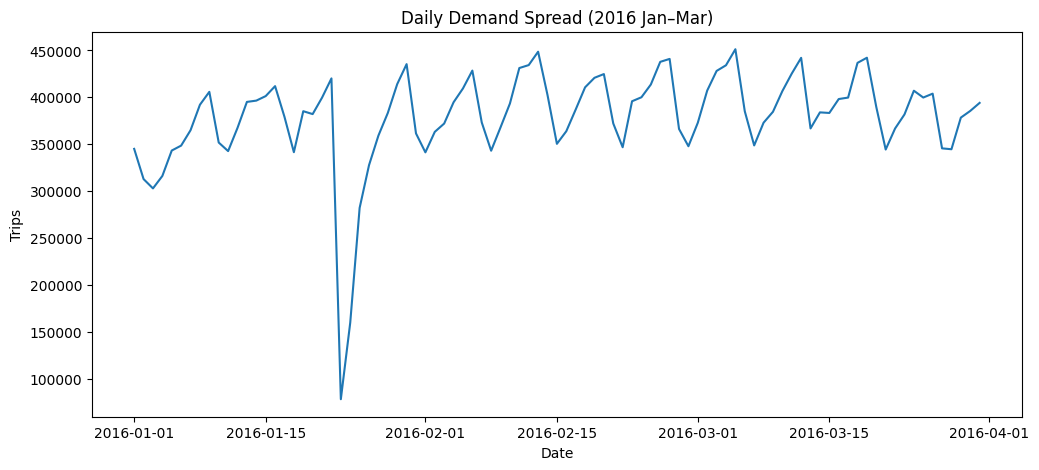

In [37]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12,5))
plt.plot(df_day_2016["day"], df_day_2016["count"])
plt.title("Daily Demand Spread (2016 Jan–Mar)")
plt.xlabel("Date")
plt.ylabel("Trips")
plt.show()

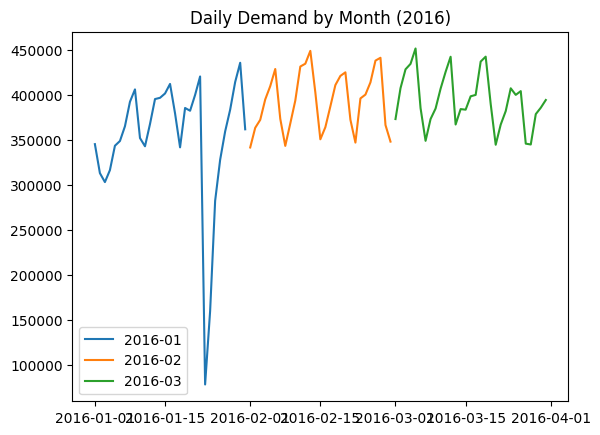

In [38]:
df_day_2016["month"] = df_day_2016["day"].dt.to_period("M")

for m in df_day_2016["month"].unique():
    subset = df_day_2016[df_day_2016["month"] == m]
    plt.plot(subset["day"], subset["count"], label=str(m))

plt.legend()
plt.title("Daily Demand by Month (2016)")
plt.show()

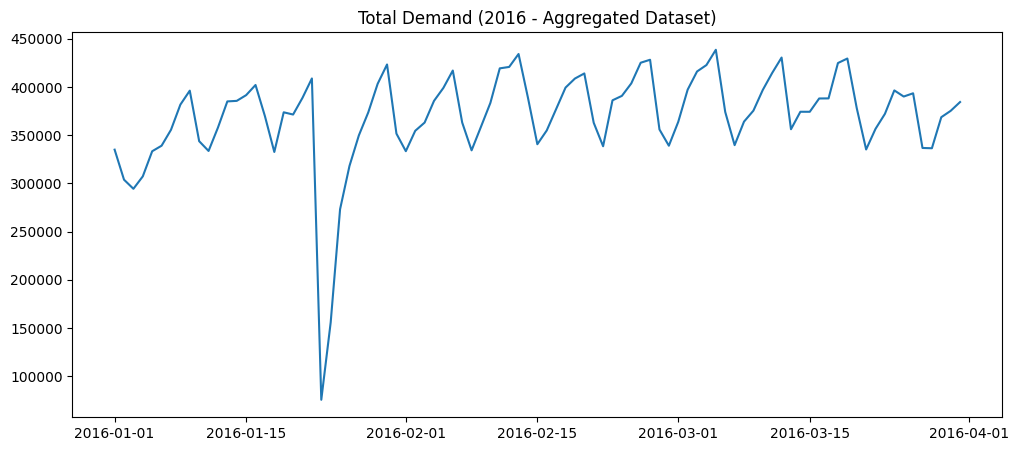

In [40]:
from pyspark.sql.functions import date_trunc, col

df_2016_demand = df_demand.filter(col("timestamp").startswith("2016"))

df_daily = df_2016_demand \
    .withColumn("day", date_trunc("day", col("timestamp"))) \
    .groupBy("day") \
    .sum("demand") \
    .orderBy("day") \
    .toPandas()

import matplotlib.pyplot as plt

plt.figure(figsize=(12,5))
plt.plot(df_daily["day"], df_daily["sum(demand)"])
plt.title("Total Demand (2016 - Aggregated Dataset)")
plt.show()

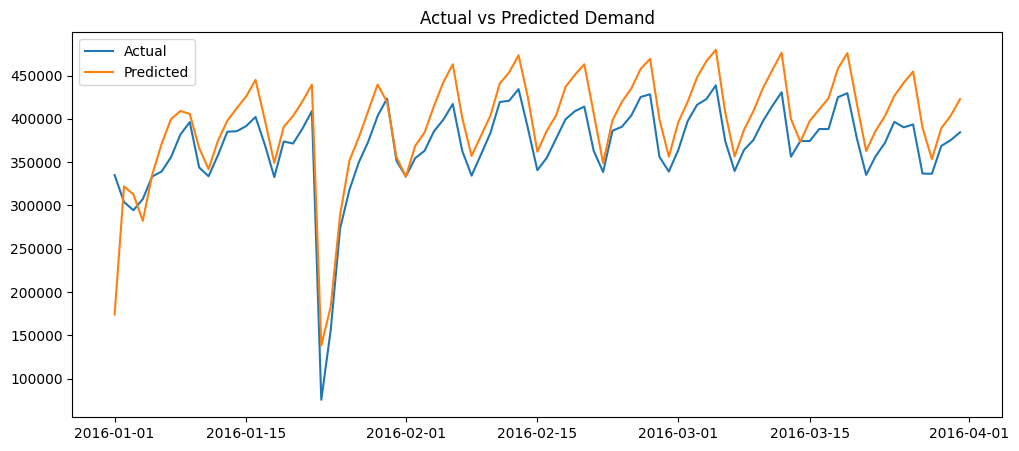

In [41]:
df_daily_pred = df_2016_demand \
    .withColumn("day", date_trunc("day", col("timestamp"))) \
    .groupBy("day") \
    .sum("demand", "final_prediction") \
    .orderBy("day") \
    .toPandas()

plt.figure(figsize=(12,5))
plt.plot(df_daily_pred["day"], df_daily_pred["sum(demand)"], label="Actual")
plt.plot(df_daily_pred["day"], df_daily_pred["sum(final_prediction)"], label="Predicted")

plt.legend()
plt.title("Actual vs Predicted Demand")
plt.show()

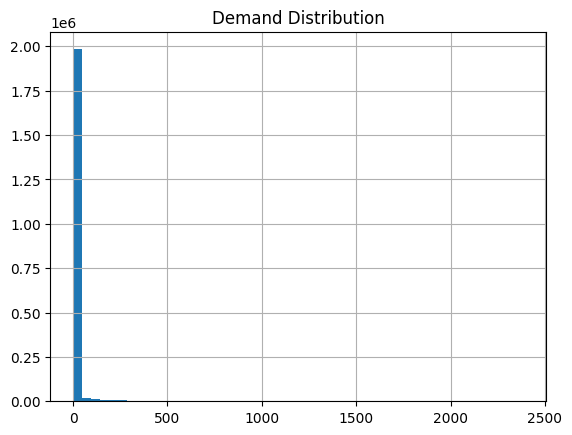

In [42]:
df_2016_demand.select("demand").toPandas().hist(bins=50)
plt.title("Demand Distribution")
plt.show()

In [43]:
top_zones = df_2016_demand \
    .groupBy("zone_id") \
    .sum("demand") \
    .orderBy("sum(demand)", ascending=False) \
    .limit(10) \
    .toPandas()

top_zones

,zone_id,sum(demand)
0,2,30982291
1,1,1510965
2,3,730313
3,4,238483
4,0,137674


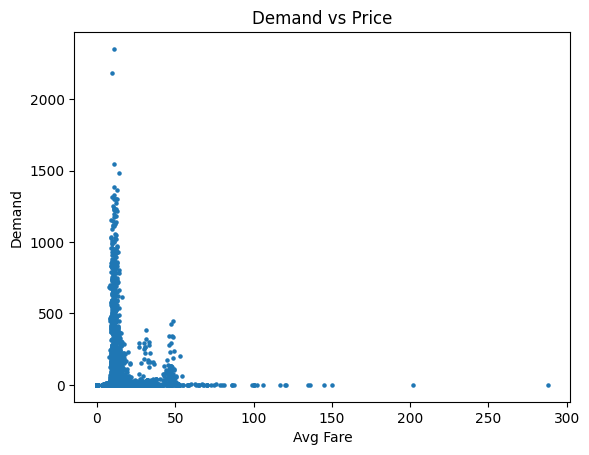

In [44]:
df_sample = df_2016_demand.sample(0.01).toPandas()

plt.scatter(df_sample["avg_fare"], df_sample["demand"], s=5)
plt.xlabel("Avg Fare")
plt.ylabel("Demand")
plt.title("Demand vs Price")
plt.show()

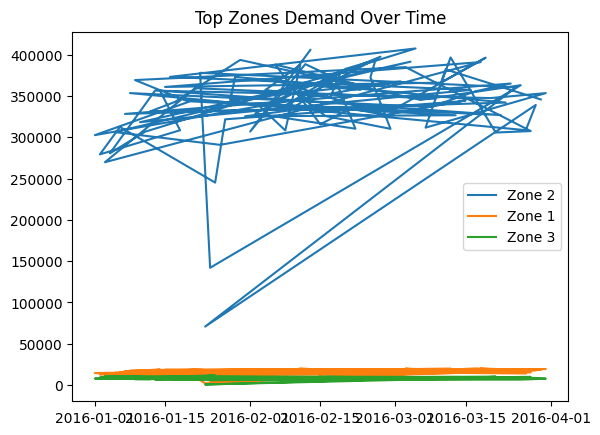

In [45]:
top_zone_ids = top_zones["zone_id"].tolist()

df_zone = df_2016_demand \
    .filter(col("zone_id").isin(top_zone_ids[:3])) \
    .withColumn("day", date_trunc("day", col("timestamp"))) \
    .groupBy("day", "zone_id") \
    .sum("demand") \
    .toPandas()

for z in top_zone_ids[:3]:
    subset = df_zone[df_zone["zone_id"] == z]
    plt.plot(subset["day"], subset["sum(demand)"], label=f"Zone {z}")

plt.legend()
plt.title("Top Zones Demand Over Time")
plt.show()

In [46]:
from pyspark.sql.functions import col

df_2016 = df_demand.filter(col("timestamp").startswith("2016"))

df_zone = df_2016 \
    .groupBy("zone_id") \
    .sum("demand") \
    .withColumnRenamed("sum(demand)", "total_demand") \
    .orderBy("total_demand", ascending=False) \
    .toPandas()

df_zone.head(10)

,zone_id,total_demand
0,2,30982291
1,1,1510965
2,3,730313
3,4,238483
4,0,137674


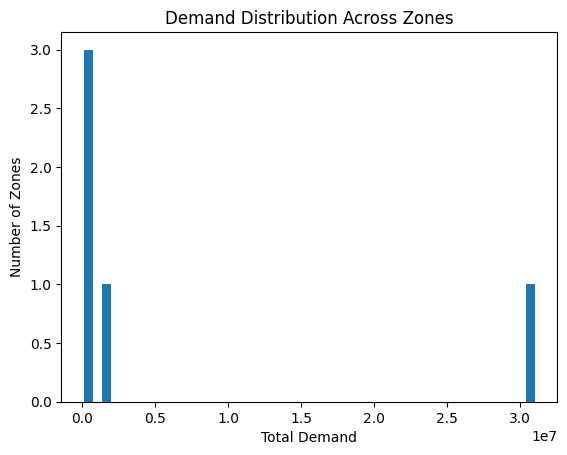

In [47]:
import matplotlib.pyplot as plt

plt.figure()
plt.hist(df_zone["total_demand"], bins=50)
plt.title("Demand Distribution Across Zones")
plt.xlabel("Total Demand")
plt.ylabel("Number of Zones")
plt.show()

In [48]:
total = df_zone["total_demand"].sum()

top5 = df_zone.head(5)["total_demand"].sum()
top10 = df_zone.head(10)["total_demand"].sum()

print("Top 5 %:", top5 / total)
print("Top 10 %:", top10 / total)

Top 5 %: 1.0
Top 10 %: 1.0


In [49]:
from pyspark.sql.functions import col

# Top 5 zones by demand
top_zones = df_2016 \
    .groupBy("lat_bin", "lon_bin") \
    .sum("demand") \
    .orderBy("sum(demand)", ascending=False) \
    .limit(5) \
    .toPandas()

In [51]:
from functools import reduce
from pyspark.sql import functions as F

condition = reduce(
    lambda a, b: a | b,
    [
        (F.col("lat_bin") == lat) & (F.col("lon_bin") == lon)
        for lat, lon in top_zone_list
    ]
)

df_zone_time = df_2016 \
    .withColumn("day", date_trunc("day", col("timestamp"))) \
    .filter(condition) \
    .groupBy("day", "lat_bin", "lon_bin") \
    .sum("demand") \
    .toPandas()

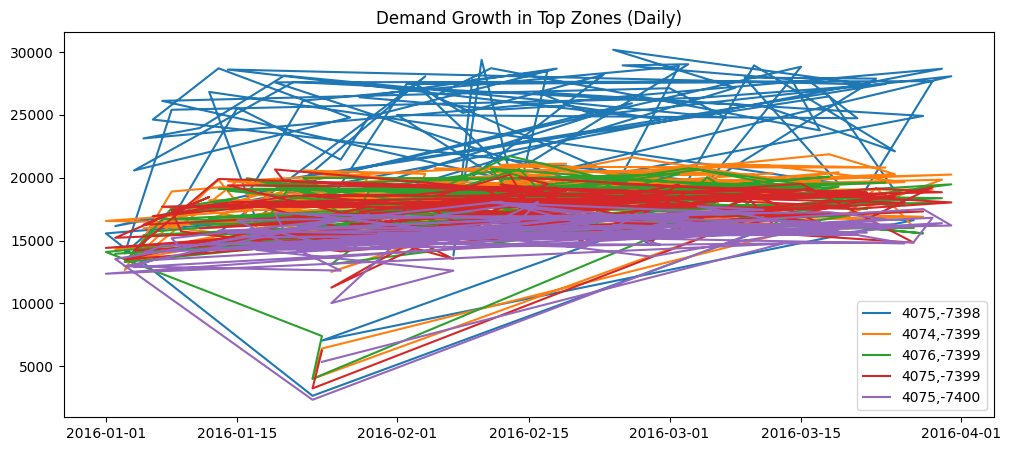

In [52]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12,5))

for (lat, lon) in top_zone_list:
    subset = df_zone_time[
        (df_zone_time["lat_bin"] == lat) &
        (df_zone_time["lon_bin"] == lon)
    ]
    
    plt.plot(subset["day"], subset["sum(demand)"], label=f"{lat},{lon}")

plt.legend()
plt.title("Demand Growth in Top Zones (Daily)")
plt.show()

In [53]:
from pyspark.sql.functions import col

df_2016 = df_demand.filter(col("timestamp").startswith("2016"))

In [55]:
df_2016.write.mode("overwrite").parquet(
    "/Users/prashant/Desktop/CRN-Taxi/processed/df_2016.parquet"
)

In [56]:
import pandas as pd

df = pd.read_parquet("/Users/prashant/Desktop/CRN-Taxi/processed/df_2016.parquet")

print("Shape:", df.shape)
df.head()

df.info()

Shape: (2070432, 44)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2070432 entries, 0 to 2070431
Data columns (total 44 columns):
 #   Column            Dtype         
---  ------            -----         
 0   lat_bin           int64         
 1   lon_bin           int64         
 2   timestamp         datetime64[ns]
 3   pickup_hour       int32         
 4   demand            int64         
 5   avg_fare          float64       
 6   avg_distance      float64       
 7   long_trip_ratio   float64       
 8   lag_1             int64         
 9   lag_2             int64         
 10  lag_3             int64         
 11  rolling_3         float64       
 12  hour              int32         
 13  day_of_week       int32         
 14  month             int32         
 15  hour_sin          float64       
 16  hour_cos          float64       
 17  loc_avg_demand    float64       
 18  loc_std_demand    float64       
 19  is_peak_hour      int32         
 20  is_weekend        int32  

In [57]:
df.describe()
df.isnull().sum().sort_values(ascending=False)

pickup_date         1699513
lat_bin                   0
log_rolling_6             0
rolling_6                 0
lag_24                    0
lag_168                   0
trend_1_3                 0
trend_1_6                 0
is_active_zone            0
peak_intensity            0
log_lag_1                 0
hour_x_zone               0
lon_bin                   0
recent_activity           0
log_demand                0
persistence               0
has_demand                0
year_month                0
zone_id                   0
pred_raw                  0
pred_log                  0
demand_zscore             0
demand_vs_avg             0
is_night                  0
lag_3                     0
timestamp                 0
pickup_hour               0
demand                    0
avg_fare                  0
avg_distance              0
long_trip_ratio           0
lag_1                     0
lag_2                     0
rolling_3                 0
is_weekend                0
hour                

In [58]:
print("Unique zones:", df[["lat_bin", "lon_bin"]].drop_duplicates().shape[0])
print("Unique timestamps:", df["timestamp"].nunique())

Unique zones: 948
Unique timestamps: 2184


In [59]:
print(df["timestamp"].min(), df["timestamp"].max())

2015-12-31 18:30:00 2016-03-31 17:30:00


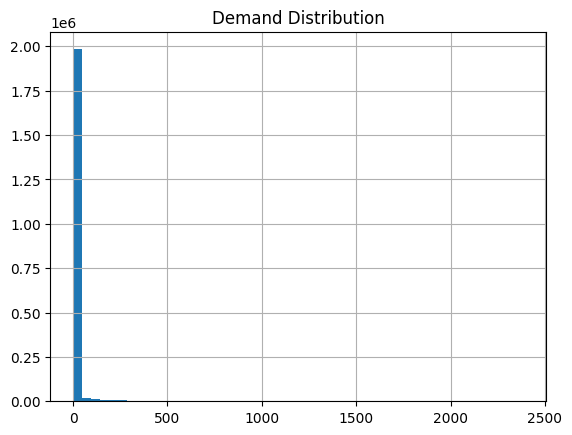

In [60]:
import matplotlib.pyplot as plt

df["demand"].hist(bins=50)
plt.title("Demand Distribution")
plt.show()

In [61]:
df.groupby("timestamp")["demand"].sum().head()

timestamp
2015-12-31 18:30:00    24530
2015-12-31 19:30:00    27636
2015-12-31 20:30:00    24646
2015-12-31 21:30:00    20509
2015-12-31 22:30:00    14780
Name: demand, dtype: int64

In [62]:
df.duplicated().sum()

0

In [63]:
df.head(20)

,lat_bin,lon_bin,timestamp,pickup_hour,demand,avg_fare,avg_distance,long_trip_ratio,lag_1,lag_2,...,recent_activity,log_demand,persistence,has_demand,pickup_date,year_month,zone_id,pred_raw,pred_log,final_prediction
0,4089,-7391,2015-12-31 18:30:00,0,0,0.0,0.0,0.0,0,0,...,0.0,0.0,0,0,None,2016-01,0,1.130484,1.990645,0.000000
1,4089,-7391,2015-12-31 19:30:00,0,0,0.0,0.0,0.0,0,0,...,0.0,0.0,0,0,None,2016-01,0,1.130484,2.002768,2.002768
2,4089,-7391,2015-12-31 20:30:00,0,0,0.0,0.0,0.0,0,0,...,0.0,0.0,0,0,None,2016-01,0,1.130484,1.985548,0.000000
3,4089,-7391,2015-12-31 21:30:00,0,0,0.0,0.0,0.0,0,0,...,0.0,0.0,0,0,None,2016-01,0,1.130484,1.963784,0.000000
4,4089,-7391,2015-12-31 22:30:00,0,0,0.0,0.0,0.0,0,0,...,0.0,0.0,0,0,None,2016-01,0,1.130484,1.963784,0.000000
5,4089,-7391,2015-12-31 23:30:00,0,0,0.0,0.0,0.0,0,0,...,0.0,0.0,0,0,None,2016-01,0,1.130484,1.984943,0.000000
6,4089,-7391,2016-01-01 00:30:00,0,0,0.0,0.0,0.0,0,0,...,0.0,0.0,0,0,None,2016-01,0,1.130484,1.984943,0.000000
7,4089,-7391,2016-01-01 01:30:00,0,0,0.0,0.0,0.0,0,0,...,0.0,0.0,0,0,None,2016-01,0,1.130484,1.984943,0.000000
8,4089,-7391,2016-01-01 02:30:00,0,0,0.0,0.0,0.0,0,0,...,0.0,0.0,0,0,None,2016-01,0,1.130484,1.984943,0.000000
9,4089,-7391,2016-01-01 03:30:00,0,0,0.0,0.0,0.0,0,0,...,0.0,0.0,0,0,None,2016-01,0,1.130484,1.967350,0.000000


In [64]:
zone_activity = df.groupby(["lat_bin","lon_bin"])["demand"].sum().reset_index()

active_zones = zone_activity[zone_activity["demand"] > 1000]

df_active = df.merge(active_zones[["lat_bin","lon_bin"]], on=["lat_bin","lon_bin"])

In [65]:
df_active.head()

,lat_bin,lon_bin,timestamp,pickup_hour,demand,avg_fare,avg_distance,long_trip_ratio,lag_1,lag_2,...,recent_activity,log_demand,persistence,has_demand,pickup_date,year_month,zone_id,pred_raw,pred_log,final_prediction
0,4077,-7400,2016-01-01 20:30:00,0,0,0.0,0.0,0.0,5,4,...,12.714286,0.0,3,0,None,2016-01,2,4.554785,3.289486,4.554785
1,4077,-7400,2016-01-01 21:30:00,0,0,0.0,0.0,0.0,0,5,...,7.857143,0.0,2,0,None,2016-01,2,8.636959,2.605808,8.636959
2,4077,-7400,2016-01-01 23:30:00,0,0,0.0,0.0,0.0,1,0,...,2.857143,0.0,2,0,None,2016-01,2,1.216945,2.732194,2.732194
3,4077,-7400,2016-01-02 23:30:00,0,0,0.0,0.0,0.0,4,1,...,9.285714,0.0,2,0,None,2016-01,2,3.654125,2.289646,3.654125
4,4077,-7400,2016-01-03 20:30:00,0,0,0.0,0.0,0.0,1,2,...,7.285714,0.0,3,0,None,2016-01,2,3.431472,2.006912,3.431472


In [71]:
zone_stats = df.groupby(["zone_id","lat_bin","lon_bin"]).agg({
    "demand": ["mean", "std", lambda x: (x > 0).mean()]
}).reset_index()

zone_stats.columns = [
    "zone_id","lat_bin","lon_bin",
    "mean_demand","std_demand","active_ratio"
]

zone_stats["cv"] = zone_stats["std_demand"] / (zone_stats["mean_demand"] + 1e-5)

In [72]:
def classify_zone(row):
    if row["active_ratio"] < 0.05:
        return "dead"
    elif row["active_ratio"] > 0.5 and row["cv"] < 2:
        return "core"
    else:
        return "intermittent"

zone_stats["zone_type"] = zone_stats.apply(classify_zone, axis=1)

In [73]:
zone_stats.groupby(["zone_id","zone_type"]).size()

zone_id  zone_type   
0        core             11
         dead            127
         intermittent     40
1        core              7
         dead            108
         intermittent      4
2        core            104
         dead             51
         intermittent     54
3        core             12
         dead            194
         intermittent     37
4        core             18
         dead            130
         intermittent     51
dtype: int64

In [74]:
zone_stats = zone_stats.merge(
    df.groupby(["lat_bin","lon_bin"])["demand"].sum().reset_index(),
    on=["lat_bin","lon_bin"]
)

zone_stats.groupby(["zone_id","zone_type"])["demand"].sum()

zone_id  zone_type   
0        core              118277
         dead                3541
         intermittent       15856
1        core             1507334
         dead                1907
         intermittent        1724
2        core            30936369
         dead                1620
         intermittent       44302
3        core              709145
         dead                4834
         intermittent       16334
4        core              207714
         dead                5409
         intermittent       25360
Name: demand, dtype: int64

In [75]:
df_eval = df.merge(
    zone_stats[["lat_bin","lon_bin","zone_type"]],
    on=["lat_bin","lon_bin"]
)

df_eval["error"] = abs(df_eval["demand"] - df_eval["final_prediction"])

df_eval.groupby("zone_type")["error"].mean()

zone_type
core            16.732707
dead             0.246349
intermittent     0.454938
Name: error, dtype: float64

In [76]:
df_eval.groupby("zone_type")[["demand","final_prediction"]].mean()

,demand,final_prediction
zone_type,,
core,100.849597,106.701569
dead,0.012994,0.251675
intermittent,0.254973,0.620399


In [78]:
df_eval["relative_error"] = abs(df_eval["demand"] - df_eval["final_prediction"]) / (df_eval["demand"] + 1)

df_eval.groupby("zone_type")["relative_error"].mean()

zone_type
core            0.631538
dead            0.240341
intermittent    0.348988
Name: relative_error, dtype: float64

In [79]:
df_eval["bias"] = df_eval["final_prediction"] - df_eval["demand"]

df_eval.groupby("zone_type")["bias"].mean()

zone_type
core            5.851972
dead            0.238681
intermittent    0.365426
Name: bias, dtype: float64

In [80]:
zone_map = zone_stats[["lat_bin", "lon_bin", "zone_type"]]

In [81]:
df_2016 = df.merge(
    zone_map,
    on=["lat_bin", "lon_bin"],
    how="left"
)

In [82]:
df_2016["zone_type"].isnull().sum()

0

In [83]:
df_2016["zone_type"].value_counts()

zone_type
dead            1332240
intermittent     406224
core             331968
Name: count, dtype: int64

In [84]:
df_2016.groupby("zone_type")["demand"].mean()

zone_type
core            100.849597
dead              0.012994
intermittent      0.254973
Name: demand, dtype: float64

In [85]:
df_2016.columns

Index(['lat_bin', 'lon_bin', 'timestamp', 'pickup_hour', 'demand', 'avg_fare',
       'avg_distance', 'long_trip_ratio', 'lag_1', 'lag_2', 'lag_3',
       'rolling_3', 'hour', 'day_of_week', 'month', 'hour_sin', 'hour_cos',
       'loc_avg_demand', 'loc_std_demand', 'is_peak_hour', 'is_weekend',
       'is_night', 'demand_vs_avg', 'demand_zscore', 'rolling_6', 'lag_24',
       'lag_168', 'trend_1_3', 'trend_1_6', 'is_active_zone', 'peak_intensity',
       'log_lag_1', 'log_rolling_6', 'hour_x_zone', 'recent_activity',
       'log_demand', 'persistence', 'has_demand', 'pickup_date', 'year_month',
       'zone_id', 'pred_raw', 'pred_log', 'final_prediction', 'zone_type'],
      dtype='object')

In [86]:
df_2016.head()

,lat_bin,lon_bin,timestamp,pickup_hour,demand,avg_fare,avg_distance,long_trip_ratio,lag_1,lag_2,...,log_demand,persistence,has_demand,pickup_date,year_month,zone_id,pred_raw,pred_log,final_prediction,zone_type
0,4089,-7391,2015-12-31 18:30:00,0,0,0.0,0.0,0.0,0,0,...,0.0,0,0,None,2016-01,0,1.130484,1.990645,0.000000,dead
1,4089,-7391,2015-12-31 19:30:00,0,0,0.0,0.0,0.0,0,0,...,0.0,0,0,None,2016-01,0,1.130484,2.002768,2.002768,dead
2,4089,-7391,2015-12-31 20:30:00,0,0,0.0,0.0,0.0,0,0,...,0.0,0,0,None,2016-01,0,1.130484,1.985548,0.000000,dead
3,4089,-7391,2015-12-31 21:30:00,0,0,0.0,0.0,0.0,0,0,...,0.0,0,0,None,2016-01,0,1.130484,1.963784,0.000000,dead
4,4089,-7391,2015-12-31 22:30:00,0,0,0.0,0.0,0.0,0,0,...,0.0,0,0,None,2016-01,0,1.130484,1.963784,0.000000,dead


In [89]:
df_2016.to_parquet(
    "/Users/prashant/Desktop/CRN-Taxi/processed/df_2016_v2.parquet",
    index=False
)

In [90]:
pd.read_parquet("/Users/prashant/Desktop/CRN-Taxi/processed/df_2016_v2.parquet")

,lat_bin,lon_bin,timestamp,pickup_hour,demand,avg_fare,avg_distance,long_trip_ratio,lag_1,lag_2,...,log_demand,persistence,has_demand,pickup_date,year_month,zone_id,pred_raw,pred_log,final_prediction,zone_type
0,4089,-7391,2015-12-31 18:30:00,0,0,0.0,0.00,0.0,0,0,...,0.000000,0,0,None,2016-01,0,1.130484,1.990645,0.000000,dead
1,4089,-7391,2015-12-31 19:30:00,0,0,0.0,0.00,0.0,0,0,...,0.000000,0,0,None,2016-01,0,1.130484,2.002768,2.002768,dead
2,4089,-7391,2015-12-31 20:30:00,0,0,0.0,0.00,0.0,0,0,...,0.000000,0,0,None,2016-01,0,1.130484,1.985548,0.000000,dead
3,4089,-7391,2015-12-31 21:30:00,0,0,0.0,0.00,0.0,0,0,...,0.000000,0,0,None,2016-01,0,1.130484,1.963784,0.000000,dead
4,4089,-7391,2015-12-31 22:30:00,0,0,0.0,0.00,0.0,0,0,...,0.000000,0,0,None,2016-01,0,1.130484,1.963784,0.000000,dead
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2070427,4088,-7391,2016-03-08 16:30:00,22,1,3.5,0.40,0.0,0,0,...,0.693147,0,1,2016-03-08,2016-03,0,1.250712,2.004239,2.004239,intermittent
2070428,4088,-7389,2016-03-08 17:30:00,23,1,8.5,1.19,0.0,0,0,...,0.693147,0,1,2016-03-08,2016-03,0,0.689603,2.072722,2.072722,dead
2070429,4088,-7388,2016-03-07 21:30:00,3,1,14.0,3.80,0.0,0,0,...,0.693147,0,1,2016-03-08,2016-03,0,0.900558,1.999897,0.000000,dead
2070430,4089,-7386,2016-03-08 12:30:00,18,1,22.0,6.36,0.0,0,0,...,0.693147,0,1,2016-03-08,2016-03,0,1.493886,2.034992,2.034992,dead


In [91]:
df = df_2016.copy()

# Remove artificial empty rows
df_real = df[df["has_demand"] == 1]

print("Original:", df.shape)
print("Real demand rows:", df_real.shape)

Original: (2070432, 45)
Real demand rows: (370919, 45)


In [92]:
# Keep only important zones
df_core = df_real[df_real["zone_type"] == "core"]
df_inter = df_real[df_real["zone_type"] == "intermittent"]